In [1]:
import mrcfile
from pathlib import Path

import torch
import numpy as np

exclude_outer_angles = True  # Exclude -90° and 90° from NCC plots and statistics

import napari

import pandas as pd

from skimage.measure import marching_cubes
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import mmdf
from torch_calculate_electrostatic_potential import (
    GridConfig,
    default_sublattice_radius,
    potential_from_structure_3d,
)
from torch_structure_manipulation import AtomicStructure, center_structure
from torch_fourier_filter.dose_weight import dose_weight_2d
from torch_ctf import calculate_ctf_2d
from torch_grid_utils import fftfreq_grid
from torch_fourier_slice import (
    backproject_2d_to_3d,
    project_3d_to_2d,
)
from torch_affine_utils.transforms_3d import Ry


In [2]:
def compute_power_spectrum(data: np.ndarray) -> np.ndarray:
    ft = np.fft.fftshift(np.fft.fftn(data))
    return np.log(np.abs(ft) + 1e-8)  # small epsilon to avoid log(0)

def simulate_pdb(pdb_id: str, device: str = "cuda") -> torch.Tensor:
    """Download a PDB entry and simulate its potential in volts (cached on disk)."""
    CACHE.mkdir(parents=True, exist_ok=True)
    volume_path = CACHE / f"{pdb_id}_box{BOX}_{PIXEL_SPACING:g}apx_peng.pt"
    if volume_path.exists():
        return torch.load(volume_path)

    structure_path = CACHE / f"{pdb_id}.cif"
    if not structure_path.exists():
        print(f"downloading {pdb_id} from RCSB ...")
        response = urllib3.PoolManager().request(
            "GET", f"https://files.rcsb.org/download/{pdb_id}.cif"
        )
        if response.status != 200:
            raise RuntimeError(f"download of {pdb_id} failed: HTTP {response.status}")
        structure_path.write_bytes(response.data)

    print(f"simulating {pdb_id}: {BOX}^3 volume at {PIXEL_SPACING} A/px ...")
    atoms = center_structure(mmdf.read(str(structure_path)), zyx=False)
    structure = AtomicStructure.from_annotated_dataframe(atoms, device=device)
    grid_3d = GridConfig.from_grid_shape_and_voxel_size(
        grid_shape=(BOX, BOX, BOX),
        voxel_size=(PIXEL_SPACING,) * 3,
        center_zyx=(0.0, 0.0, 0.0),
        sublattice_radius=default_sublattice_radius(PIXEL_SPACING),
        device=torch.device(device),
    )
    volume = potential_from_structure_3d(
        structure, grid_3d,
        scattering_factors="peng_bonded", bonded_fallback="elemental",
    ).cpu()
    torch.save(volume, volume_path)
    return volume

## Visualize reconstructed tomograms

In [3]:
base_path = Path("C:/Users/ruben/OneDrive - Delft University of Technology/Documenten/Nanobiology 6/ARP/phantom_tomogram_13_10/")

ddw_refined_tomograms = {}
ddw_fourier_refined_tomograms = {}
ic_refined_tomograms = {}
ic_fourier_refined_tomograms = {}
no_noise_tomograms = {}
fourier_no_noise_tomograms = {}
noise_tomograms = {}
fourier_noise_tomograms = {}


for n in range(0,4):
    refined_tomopath = base_path / f"ddw/noisy_phantom_tomo_id{n}_even+noisy_phantom_tomo_id{n}_odd_refined.mrc"
    with mrcfile.open(refined_tomopath) as mrc:
        refined_tomogram_tensor = torch.tensor(mrc.data, dtype=torch.float32)
        ddw_refined_tomograms[n] = refined_tomogram_tensor
        ddw_fourier_refined_tomograms[n] = compute_power_spectrum(refined_tomogram_tensor)

    refined_tomopath = base_path / f"icecream/latest_prediction_noisy_phantom_tomo_id{n}_even_noisy_phantom_tomo_id{n}_odd.mrc"
    with mrcfile.open(refined_tomopath) as mrc:
        refined_tomogram_tensor = torch.tensor(mrc.data, dtype=torch.float32)
        ic_refined_tomograms[n] = refined_tomogram_tensor
        ic_fourier_refined_tomograms[n] = compute_power_spectrum(refined_tomogram_tensor)

    no_noise_tomopath = base_path / f"no_noise/no_noise_phantom_tomo_id{n}.mrc"
    with mrcfile.open(no_noise_tomopath) as mrc:
        no_noise_tomogram_tensor = torch.tensor(mrc.data, dtype=torch.float32)
        no_noise_tomograms[n] = no_noise_tomogram_tensor
        fourier_no_noise_tomograms[n] = compute_power_spectrum(no_noise_tomogram_tensor)

    noise_tomopath_even = base_path / f"even/noisy_phantom_tomo_id{n}_even.mrc"
    with mrcfile.open(noise_tomopath_even) as mrc:
        noise_tomogram_tensor_even = torch.tensor(mrc.data, dtype=torch.float32)
    noise_tomopath_odd = base_path / f"odd/noisy_phantom_tomo_id{n}_odd.mrc"
    with mrcfile.open(noise_tomopath_odd) as mrc:
        noise_tomogram_tensor_odd = torch.tensor(mrc.data, dtype=torch.float32)

    noise_tomograms[n] = (noise_tomogram_tensor_even + noise_tomogram_tensor_odd)/2
    fourier_noise_tomograms[n] = compute_power_spectrum(noise_tomograms[n])

In [5]:
# a = napari.Viewer()
# for n in range(0,4):
#     if n == 3:
# #         # a.add_image(refined_tomograms[n], name=f"subtomo {n}")
# #         # a.add_image(fourier_refined_tomograms[n], name=f"fourier ref {n}")
#         a.add_image(noise_tomograms[n], name=f"No noise {n}")
# #         # a.add_image(fourier_noise_tomograms[n], name=f"Fourier no noise {n}")
#         a.add_image(no_noise_tomograms[n], name=f"No noise {n}")
# #         # a.add_image(fourier_noise_tomograms[n], name=f"Fourier no noise {n}")


## Load ground truth proteins

In [4]:
## load proteins
PDB_ID_ribosome = "4v6x"  # 80S ribosome
PDB_ID_cohesin = "6wg3"  # Cohesin complex
PIXEL_SPACING = 10.0 # angstroms per pixel -> Nyquist at 20.0 A
# VOLTAGE = 300  # in keV
BOX = 96  # 1280 A box
CACHE = Path.home() / ".cache" / "arp"


ribosome = np.array(simulate_pdb(PDB_ID_ribosome, device="cpu"))
cohesin = np.array(simulate_pdb(PDB_ID_cohesin, device="cpu"))

box_size = ribosome.shape[0]
center = box_size // 2

# Precompute squared distance grid
z, y, x = np.ogrid[:box_size, :box_size, :box_size]
dist_sq = (x - center)**2 + (y - center)**2 + (z - center)**2

last_active_radius = 0

for volume in [ribosome, cohesin]:
    for r in range(center + 1):
        if r == 0:
            shell_mask = (dist_sq == 0)
        else:
            lower_bound = (r - 0.5) ** 2
            upper_bound = (r + 0.5) ** 2
            shell_mask = (dist_sq >= lower_bound) & (dist_sq < upper_bound)
        
        # Check how much ribosome space exists in this specific shell
        ribosome_in_shell = np.sum(volume[shell_mask])
        
        if ribosome_in_shell > 0:
            last_active_radius = r
        else:
            # Once we hit an empty shell beyond the core, we can see if it stays empty
            # (Optional: break early if you are sure there's no hollow outer layers)
            pass

    print(f"The ribosome takes up no space starting from radius: {last_active_radius + 1}")
    print(f"So that means maximum diameter is {last_active_radius*2*10} Angstrom")


C:\Users\ruben\AppData\Local\Temp\ipykernel_27332\1835839156.py:10: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  ribosome = np.array(simulate_pdb(PDB_ID_ribosome, device="cpu"))
C:\Users\ruben\AppData\Local\Temp\ipykernel_27332\1835839156.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  cohesin = np.array(simulate_pdb(PDB_ID_cohesin, device="cpu"))


The ribosome takes up no space starting from radius: 26
So that means maximum diameter is 500 Angstrom
The ribosome takes up no space starting from radius: 15
So that means maximum diameter is 280 Angstrom


## Localize and analyze proteins

In [5]:
protein_data = pd.read_csv(base_path / "protein_data.csv")
protein_data.head(5)

r_rib, r_coh = 26, 15
ribosome_small = ribosome[center-r_rib:center+r_rib+1, center-r_rib:center+r_rib+1, center-r_rib:center+r_rib+1]
cohesin_small = cohesin[center-r_coh:center+r_coh+1, center-r_coh:center+r_coh+1, center-r_coh:center+r_coh+1]

In [6]:
import re
def parse_loc(s):
    return [int(v) for v in re.findall(r"-?\d+", s.replace("np.int64", ""))]

from scipy.ndimage import affine_transform

def parse_rot(s):
    return np.array([float(v) for v in re.findall(r"-?\d+\.?\d*(?:e-?\d+)?", s)]).reshape(3, 3)

def unrotate(sub, R, zyx=True, center_offset_zyx=None):
    if zyx:                      # matrix given in (x,y,z); volume indexed (z,y,x)
        P = np.eye(3)[::-1]; R = P @ R @ P
    c = (np.array(sub.shape) - 1) / 2
    # affine_transform maps output->input coords, so passing R undoes the rotation R
    offset = c - R @ c
    if center_offset_zyx is not None:
        offset -= R @ center_offset_zyx
    return affine_transform(sub, R, offset=offset, order=1)

def ground_truth_center_offset_zyx(vol, threshold=0.05):
    v = vol.transpose(2, 1, 0)                     # frame used during placement (x, y, z)
    nz = np.argwhere(v >= threshold)
    p_center = (nz.min(0) + nz.max(0)) / 2         # rotation centre used in placement
    delta = p_center - (np.array(v.shape) - 1) / 2
    return delta[::-1]                              # to (z, y, x)

In [7]:
rib_list = []
rib_rotations = []

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "cohesin":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = ddw_refined_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 26
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        rib_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + rib_vol.shape[0],
            y_start:y_start + rib_vol.shape[1],
            x_start:x_start + rib_vol.shape[2],
        ]

        rib_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        rib_rotations.append(parse_rot(line['rotation']))
        rib_list.append((i, rib_vol))

coh_list = []
coh_rotations = []

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "ribosome":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = ddw_refined_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 15
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        coh_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + coh_vol.shape[0],
            y_start:y_start + coh_vol.shape[1],
            x_start:x_start + coh_vol.shape[2],
        ]

        coh_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        coh_list.append((i, coh_vol))
        coh_rotations.append(parse_rot(line['rotation']))

def extract_refined_proteins(tomograms, radius, excluded_protein_name):
    protein_list = []
    rotations = []

    for i in range(4):
        subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
        vol = tomograms[i].numpy()
        z_vol, y_vol, x_vol = vol.shape

        for _, line in subtomo_proteins.iterrows():
            if line["protein_name"] == excluded_protein_name:
                continue

            x, y, z = parse_loc(line["sub_loc"])
            if (x < radius or x + radius >= x_vol or
                y < radius or y + radius >= y_vol or
                z < radius or z + radius >= z_vol):
                continue

            z_start, y_start, x_start = z - radius, y - radius, x - radius
            protein_vol = vol[
                z_start:z + radius + 1,
                y_start:y + radius + 1,
                x_start:x + radius + 1,
            ].copy()
            zz, yy, xx = np.ogrid[
                z_start:z_start + protein_vol.shape[0],
                y_start:y_start + protein_vol.shape[1],
                x_start:x_start + protein_vol.shape[2],
            ]
            protein_vol[
                (zz - z) ** 2 + (yy - y) ** 2 + (xx - x) ** 2 > radius ** 2
            ] = 0

            protein_list.append((i, protein_vol))
            rotations.append(parse_rot(line["rotation"]))

    return protein_list, rotations


ic_rib_list, ic_rib_rotations = extract_refined_proteins(
    ic_refined_tomograms, r_rib, "cohesin"
)
ic_coh_list, ic_coh_rotations = extract_refined_proteins(
    ic_refined_tomograms, r_coh, "ribosome"
)

ribosome 115 66 50
ribosome 38 210 35
ribosome 126 224 71
ribosome 142 187 73
ribosome 40 63 55
ribosome 158 37 72
ribosome 91 40 72
ribosome 228 34 46
ribosome 227 83 34
ribosome 82 208 58
ribosome 33 184 56
ribosome 54 155 53
ribosome 174 225 68
ribosome 110 157 30
ribosome 171 108 33
ribosome 136 130 44
ribosome 172 64 44
ribosome 93 125 70
ribosome 196 184 60
ribosome 74 85 26
ribosome 199 76 31
ribosome 155 165 35
ribosome 176 146 46
ribosome 142 108 31
ribosome 170 158 45
ribosome 110 177 72
ribosome 68 124 55
ribosome 86 47 32
ribosome 100 152 38
ribosome 208 205 59
ribosome 62 35 63
ribosome 114 78 65
ribosome 193 114 52
ribosome 171 229 33
ribosome 222 146 51
ribosome 135 136 55
ribosome 34 135 42
ribosome 215 63 38
ribosome 167 131 35
ribosome 81 166 55
ribosome 36 209 37
ribosome 86 107 57
ribosome 154 107 70
ribosome 208 90 50
ribosome 107 163 70
ribosome 41 107 50
ribosome 139 96 35
ribosome 63 92 52
ribosome 96 38 26
ribosome 60 57 64
ribosome 96 93 45
ribosome 80 205 70


[10.94881408 -8.7706628  -9.42610957]
[ 29.98563271 -77.76871658 120.98025046]
concentration: 0.4261524564446927


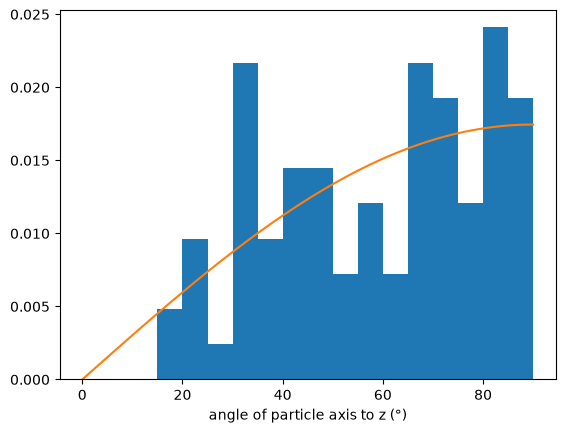

[ 16.75496171   3.39546084 -38.68386393]
[-133.36491263   19.20230747  -50.08364218]
concentration: 0.4183128186700114


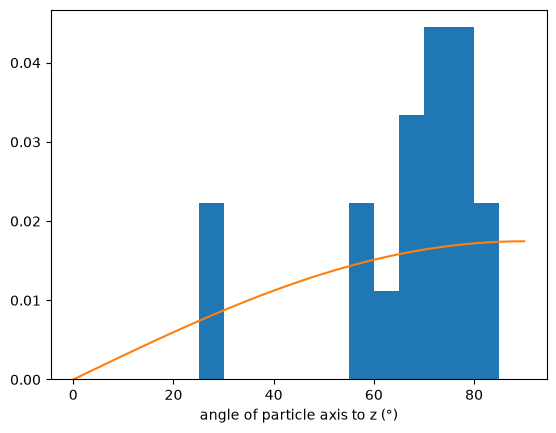

In [8]:
from scipy.spatial.transform import Rotation

## Analyze orientation distribution
for rots in [rib_rotations, coh_rotations]:
    rotations = Rotation.from_matrix(np.array(rots))

    # Get all the euler angles from the rotations
    all_angles = rotations.as_euler('xyz', degrees=True)

    print(all_angles.mean(0))
    # 1. Proper mean rotation: its "strength" is ~0 for random, ~1 if all aligned
    
    mean_rot = rotations.mean()
    print(mean_rot.as_euler("xyz", degrees=True))
    q = rotations.as_quat(); q *= np.sign(q[:, 3:4])            # fix the q/-q ambiguity
    print("concentration:", np.linalg.norm(q.mean(0)))           # ~0.5 for uniform, 1 = identical

    # 2. Where each ribosome's own z-axis points (should cover the sphere evenly)
    v = rotations.apply([0, 0, 1])
    tilt = np.degrees(np.arccos(np.abs(v[:, 2])))                # angle to the beam axis
    plt.hist(tilt, bins=18, range=(0, 90), density=True)
    t = np.linspace(0, 90, 100); plt.plot(t, np.sin(np.radians(t)) * np.pi / 180)  # uniform expectation
    plt.xlabel("angle of particle axis to z (°)"); plt.show()

## Extract ground truth proteins

In [9]:
# no_noise_tomograms

rib_list_no_noise = []

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "cohesin":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = no_noise_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 26
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        rib_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + rib_vol.shape[0],
            y_start:y_start + rib_vol.shape[1],
            x_start:x_start + rib_vol.shape[2],
        ]

        rib_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        # rib_vol_unrot = unrotate(
        #     rib_vol,
        #     parse_rot(line["rotation"]),
        #     center_offset_zyx=rib_center_offset_zyx,
        # )

        rib_list_no_noise.append((i, rib_vol))

coh_list_no_noise = []
coh_center_offset_zyx = ground_truth_center_offset_zyx(cohesin)

for i in range(0,4):
    subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
    for index, line in subtomo_proteins.iterrows():

        if line["protein_name"] == "ribosome":
            continue

        x, y, z = parse_loc(line["sub_loc"])

        vol = no_noise_tomograms[i].numpy()
        # print(vol.shape)                       # mrcfile gives (z, y, x)
        r = 15
        z_vol, y_vol, x_vol = vol.shape
        if (x < r or x + r >= x_vol or
            y < r or y + r >= y_vol or
            z < r or z + r >= z_vol):
            continue

        print(line["protein_name"], x, y, z)
        z_start, y_start, x_start = z-r, y-r, x-r
        coh_vol = vol[z_start:z+r+1, y_start:y+r+1, x_start:x+r+1].copy()
        zz, yy, xx = np.ogrid[
            z_start:z_start + coh_vol.shape[0],
            y_start:y_start + coh_vol.shape[1],
            x_start:x_start + coh_vol.shape[2],
        ]

        coh_vol[(zz-z)**2 + (yy-y)**2 + (xx-x)**2 > r**2] = 0

        # coh_vol_unrot = unrotate(
        #     coh_vol,
        #     parse_rot(line["rotation"]),
        #     center_offset_zyx=coh_center_offset_zyx
        # )

        coh_list_no_noise.append((i, coh_vol))

ribosome 115 66 50
ribosome 38 210 35
ribosome 126 224 71
ribosome 142 187 73
ribosome 40 63 55
ribosome 158 37 72
ribosome 91 40 72
ribosome 228 34 46
ribosome 227 83 34
ribosome 82 208 58
ribosome 33 184 56
ribosome 54 155 53
ribosome 174 225 68
ribosome 110 157 30
ribosome 171 108 33
ribosome 136 130 44
ribosome 172 64 44
ribosome 93 125 70
ribosome 196 184 60
ribosome 74 85 26
ribosome 199 76 31
ribosome 155 165 35
ribosome 176 146 46
ribosome 142 108 31
ribosome 170 158 45
ribosome 110 177 72
ribosome 68 124 55
ribosome 86 47 32
ribosome 100 152 38
ribosome 208 205 59
ribosome 62 35 63
ribosome 114 78 65
ribosome 193 114 52
ribosome 171 229 33
ribosome 222 146 51
ribosome 135 136 55
ribosome 34 135 42
ribosome 215 63 38
ribosome 167 131 35
ribosome 81 166 55
ribosome 36 209 37
ribosome 86 107 57
ribosome 154 107 70
ribosome 208 90 50
ribosome 107 163 70
ribosome 41 107 50
ribosome 139 96 35
ribosome 63 92 52
ribosome 96 38 26
ribosome 60 57 64
ribosome 96 93 45
ribosome 80 205 70


In [10]:
def extract_noise_proteins(radius, excluded_protein_name):
    protein_list = []

    for i in range(4):
        subtomo_proteins = protein_data[protein_data["subtomo_id"] == i]
        vol = noise_tomograms[i].cpu().numpy()

        for _, line in subtomo_proteins.iterrows():
            if line["protein_name"] == excluded_protein_name:
                continue

            x, y, z = parse_loc(line["sub_loc"])
            z_vol, y_vol, x_vol = vol.shape
            if (x < radius or x + radius >= x_vol or
                y < radius or y + radius >= y_vol or
                z < radius or z + radius >= z_vol):
                continue

            z_start, y_start, x_start = z - radius, y - radius, x - radius
            protein_vol = vol[
                z_start:z + radius + 1,
                y_start:y + radius + 1,
                x_start:x + radius + 1,
            ].copy()
            zz, yy, xx = np.ogrid[
                z_start:z_start + protein_vol.shape[0],
                y_start:y_start + protein_vol.shape[1],
                x_start:x_start + protein_vol.shape[2],
            ]
            protein_vol[
                (zz - z) ** 2 + (yy - y) ** 2 + (xx - x) ** 2 > radius ** 2
            ] = 0
            protein_list.append((i, protein_vol))

    return protein_list


rib_list_noise = extract_noise_proteins(r_rib, "cohesin")
coh_list_noise = extract_noise_proteins(r_coh, "ribosome")

In [32]:

a = napari.Viewer()
a.add_image(rib_list_noise[4][1], name="noisy")
a.add_image(compute_power_spectrum(rib_list_noise[4][1]), name="noisy F")
a.add_image(rib_list[4][1], name="icecream ")
a.add_image(compute_power_spectrum(rib_list[4][1]), name="icecream F")
a.add_image(ic_rib_list[4][1], name="ddw")
a.add_image(compute_power_spectrum(ic_rib_list[4][1]), name="ddw F")
a.add_image(rib_list_no_noise[4][1], name="no noisy")
a.add_image(compute_power_spectrum(rib_list_no_noise[4][1]), name="no noisy F")



<Image layer 'no noisy F' at 0x21fc67e47d0>

## Compare the proteins

In [11]:
from torch_fourier_slice.slice_extraction._extract_central_slices_rfft_3d import (
    extract_central_slices_rfft_3d,
)
from torch_ctf import calculate_ctf_2d
from torch_grid_utils import fftfreq_grid



def rotation_matrix_y(angle_deg, device="cpu"):
    theta = torch.deg2rad(torch.tensor(float(angle_deg), device=device))
    c, s = torch.cos(theta), torch.sin(theta)
    return torch.stack([
        torch.stack([ c, torch.tensor(0.0, device=device),  s]),
        torch.stack([ torch.tensor(0.0, device=device), torch.tensor(1.0, device=device), torch.tensor(0.0, device=device)]),
        torch.stack([-s, torch.tensor(0.0, device=device),  c]),
    ])

def extract_slices(volume, angles):
    """
    Extract slices from a 3D volume at specified angles.

    Parameters
    ----------
    volume : torch.Tensor
        The 3D volume from which to extract slices.
    angles : list
        A list of angles (in degrees) at which to extract slices.

    Returns
    -------
    torch.Tensor
        A tensor containing the extracted slices.
    """

    rotation_matrices = torch.stack([rotation_matrix_y(a) for a in angles])

    return extract_central_slices_rfft_3d(volume, rotation_matrices)

In [12]:

# need to add minus sign for correct CTF, weird...
VOLTAGE = 300

ctf_values = {
    "defocus": 3,  # in micrometers
    "astigmatism": 0.0,  # in micrometers
    "astigmatism_angle": 0.0,  # in degrees
    "voltage": VOLTAGE,  # in volts
    "spherical_aberration": 2.7, # mm float | torch.Tensor,
    "amplitude_contrast": 0.07, # float | torch.Tensor,
    "phase_shift": 0.0, # float | torch.Tensor,
    "pixel_size": PIXEL_SPACING, # float | torch.Tensor,
    # "image_shape": (BOX, BOX), # tuple[int, int],
    "rfft": True, # bool,
    "fftshift": False, # bool,
    "beam_tilt_mrad": None, # torch.Tensor | None = None,
    "even_zernike_coeffs": None, # dict | None = None,
    "odd_zernike_coeffs": None, # dict | None = None,
    "transform_matrix": None, # torch.Tensor | None = None,
    "return_complex_ctf": False, # bool = False, 
}

d_rib = r_rib*2
ctf_image_rib = - calculate_ctf_2d(**ctf_values, image_shape=(d_rib, d_rib))
frequency_grid = fftfreq_grid(image_shape=(d_rib, d_rib), rfft=True, fftshift=False, norm=True)
ctf_image_rib[frequency_grid > 0.5] = 0

print(np.shape(ctf_image_rib))

d_coh = r_coh*2
ctf_image_coh = - calculate_ctf_2d(**ctf_values, image_shape=(d_coh, d_coh))
frequency_grid = fftfreq_grid(image_shape=(d_coh, d_coh), rfft=True, fftshift=False, norm=True)
ctf_image_coh[frequency_grid > 0.5] = 0

print(np.shape(ctf_image_coh))

torch.Size([52, 27])
torch.Size([30, 16])


In [13]:
def apply_ctf(slices, ctf_values, flip_sign=False):
    s = torch.as_tensor(slices, dtype=torch.float32)
    h, w = s.shape[-2:]
    ctf = -calculate_ctf_2d(**{**ctf_values, "rfft": True, "fftshift": False}, image_shape=(h, w))
    frequency_grid = fftfreq_grid(
        image_shape=(h,w), rfft=True, fftshift=False, norm=True
    )
    ctf[frequency_grid > 0.5] = 0
    return torch.fft.irfft2(torch.fft.rfft2(s) * torch.abs(ctf), s=(h, w))

def ncc(a, b):
    a = a - a.mean(dim=(-2, -1), keepdim=True)
    b = b - b.mean(dim=(-2, -1), keepdim=True)
    return (a * b).sum(dim=(-2, -1)) / torch.sqrt((a**2).sum(dim=(-2, -1)) * (b**2).sum(dim=(-2, -1)))

def compare_proteins_with_NCC(protein_list, ground_truth_list):

    particle_ncc = []
    i = 0
    for (_, protein_vol), (_, ground_truth_vol) in zip(
        protein_list, ground_truth_list
    ):

        protein = torch.as_tensor(protein_vol, dtype=torch.float32)

        clean = torch.as_tensor(ground_truth_vol, dtype=torch.float32)

        protein_projection = project_3d_to_2d(protein, rotation_matrices=R)
        
        clean_projection = project_3d_to_2d(clean, rotation_matrices=R)
        clean_ctf = apply_ctf(clean_projection, ctf_values)
        particle_ncc.append(ncc(protein_projection, clean_ctf))

        # i += 1
        # if i == 2:
        #     fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        #     # 1. Even/odd tomo
        #     axes[0].imshow(protein_projection[91], cmap="gray")
        #     axes[0].set_title("Noisy")
        #     axes[0].axis("off")  # Optional: hides axis ticks for a cleaner look

        #     # 2. No noise sim
        #     axes[1].imshow(clean_ctf[91], cmap="gray")
        #     axes[1].set_title("Sim + CTF")
        #     axes[1].axis("off")
        #     plt.tight_layout()
        #     plt.show()

    return torch.stack(particle_ncc)

In [14]:
## claude
import torch.nn.functional as F

def apply_ctf(images, ctf_values, pad=0):
    """Apply |CTF| to 2D projections, optionally reflect-padding to avoid edge ringing."""
    s = torch.as_tensor(images, dtype=torch.float32)
    h, w = s.shape[-2:]
    if pad > 0:
        s = F.pad(s, (pad, pad, pad, pad), mode="reflect")   # (N, H, W) -> padded
    H, W = s.shape[-2:]
    ctf = calculate_ctf_2d(**{**ctf_values, "rfft": True, "fftshift": False},
                        image_shape=(H, W))
    freq = fftfreq_grid(image_shape=(H, W), rfft=True, fftshift=False, norm=True)
    ctf[freq > 0.5] = 0
    out = torch.fft.irfft2(torch.fft.rfft2(s) * torch.abs(ctf), s=(H, W))
    return out[..., pad:pad + h, pad:pad + w] if pad > 0 else out


def circular_mask(shape, radius, soft_edge=0.0):
    """2D circular mask centred on the box; optional cosine fall-off of width soft_edge px."""
    h, w = shape
    yy = torch.arange(h) - (h - 1) / 2
    xx = torch.arange(w) - (w - 1) / 2
    rr = torch.sqrt(yy[:, None] ** 2 + xx[None, :] ** 2)
    if soft_edge <= 0:
        return (rr <= radius).float()
    t = ((rr - (radius - soft_edge)) / soft_edge).clamp(0, 1)
    return 0.5 * (1 + torch.cos(torch.pi * t))


def masked_ncc(a, b, mask):
    """NCC computed only inside the mask (mean subtracted over the masked region)."""
    w = mask / mask.sum()
    a = a - (a * w).sum(dim=(-2, -1), keepdim=True)
    b = b - (b * w).sum(dim=(-2, -1), keepdim=True)
    num = (mask * a * b).sum(dim=(-2, -1))
    den = torch.sqrt((mask * a**2).sum(dim=(-2, -1)) * (mask * b**2).sum(dim=(-2, -1)))
    return num / den


def compare_proteins_with_NCC(protein_list, ground_truth_list, radius, R, ctf_values,
                            reflect_pad=True, soft_edge=0.0):
    ncc_all = []
    i = 0
    for (_, vol), (_, gt) in zip(protein_list, ground_truth_list):
        proj    = project_3d_to_2d(torch.as_tensor(vol, dtype=torch.float32), rotation_matrices=R)
        gt_proj = project_3d_to_2d(torch.as_tensor(gt,  dtype=torch.float32), rotation_matrices=R)

        # 1) CTF on the full, unmasked GT projection (reflect-padded)
        pad = gt_proj.shape[-1] // 2 if reflect_pad else 0
        gt_ctf = apply_ctf(gt_proj, ctf_values, pad=pad)

        # 2) only now the circular mask, identical for both
        mask = circular_mask(proj.shape[-2:], radius, soft_edge)
        ncc_all.append(masked_ncc(proj, gt_ctf, mask))

        i += 1
        if i == 2:
            fig, axes = plt.subplots(1, 2, figsize=(15, 5))

            # 1. Even/odd tomo
            axes[0].imshow(proj[-1], cmap="gray")
            axes[0].set_title("Noisy")
            axes[0].axis("off")  # Optional: hides axis ticks for a cleaner look

            # 2. No noise sim
            axes[1].imshow(gt_ctf[-1], cmap="gray")
            axes[1].set_title("Sim + CTF")
            axes[1].axis("off")
            plt.tight_layout()
            plt.show()
    return torch.stack(ncc_all)

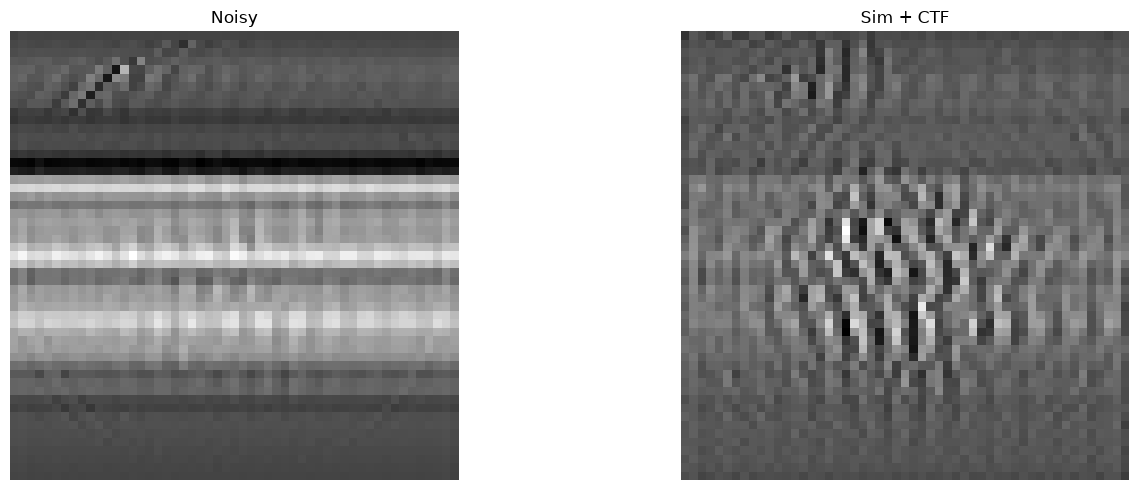

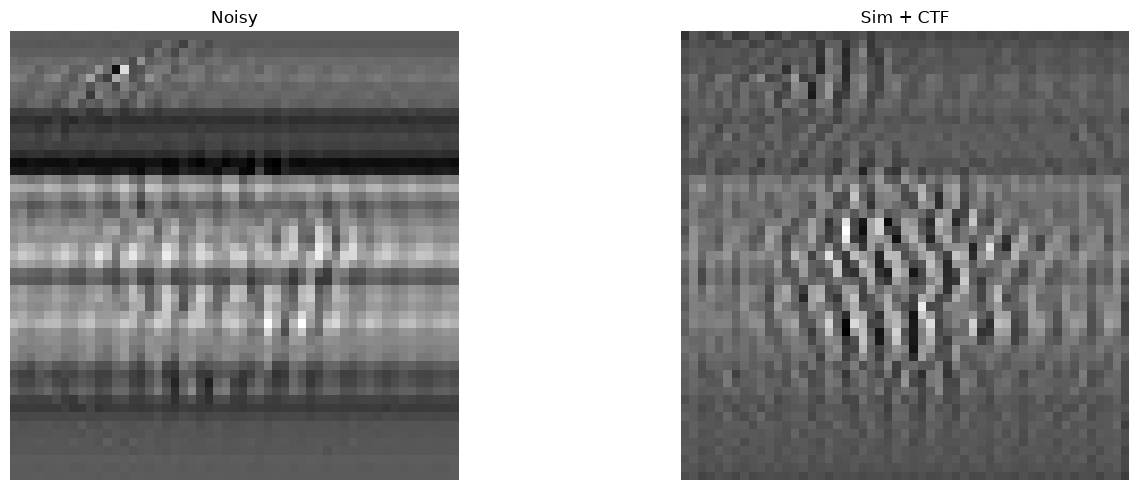

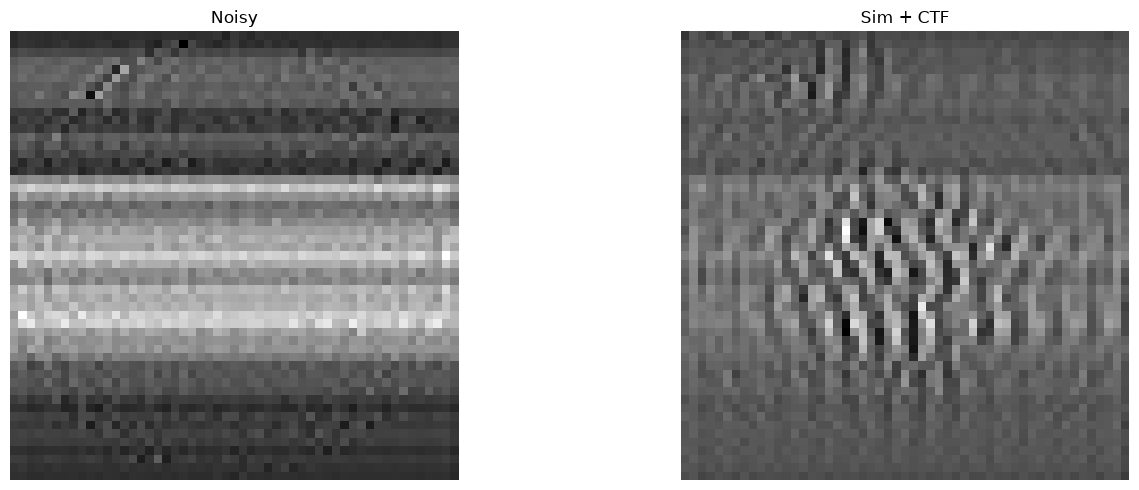

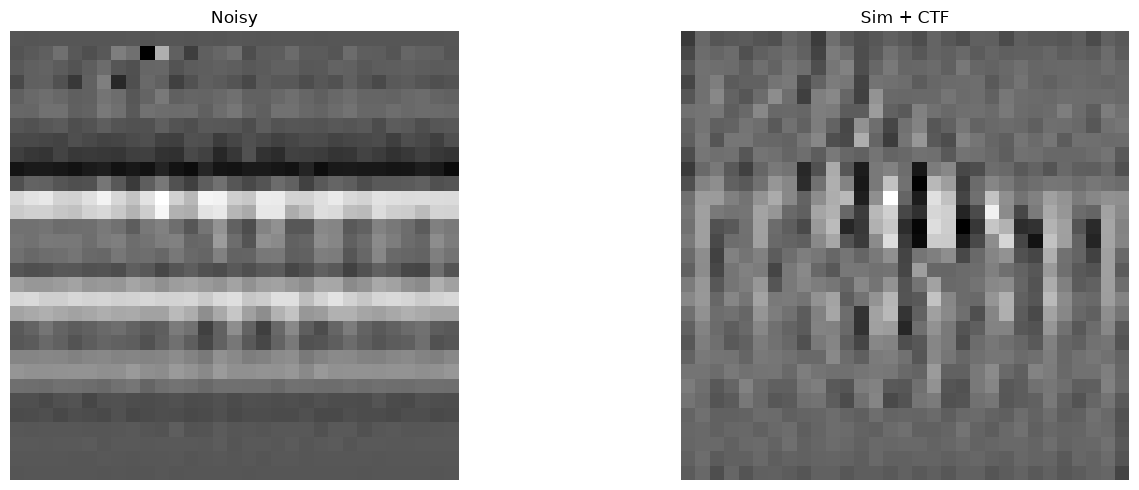

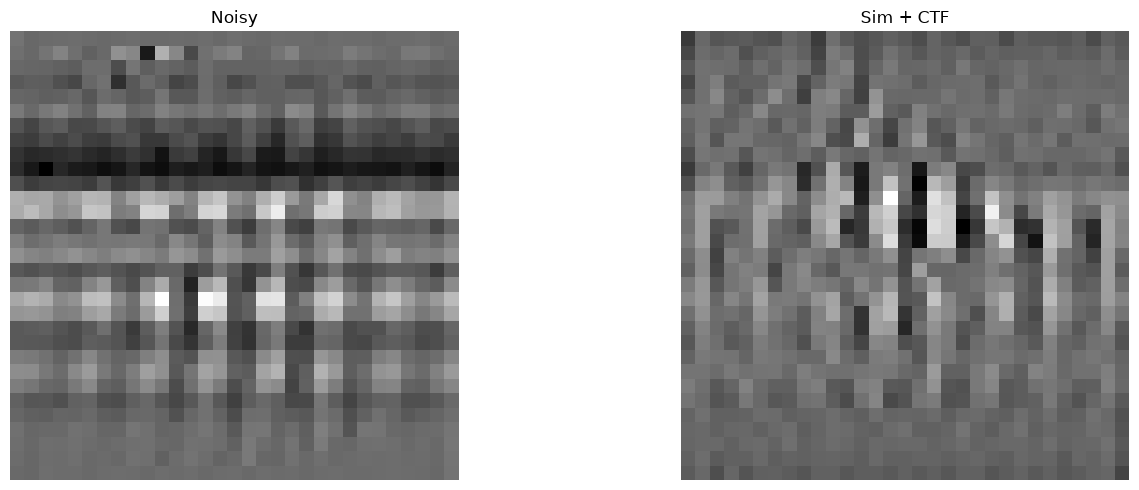

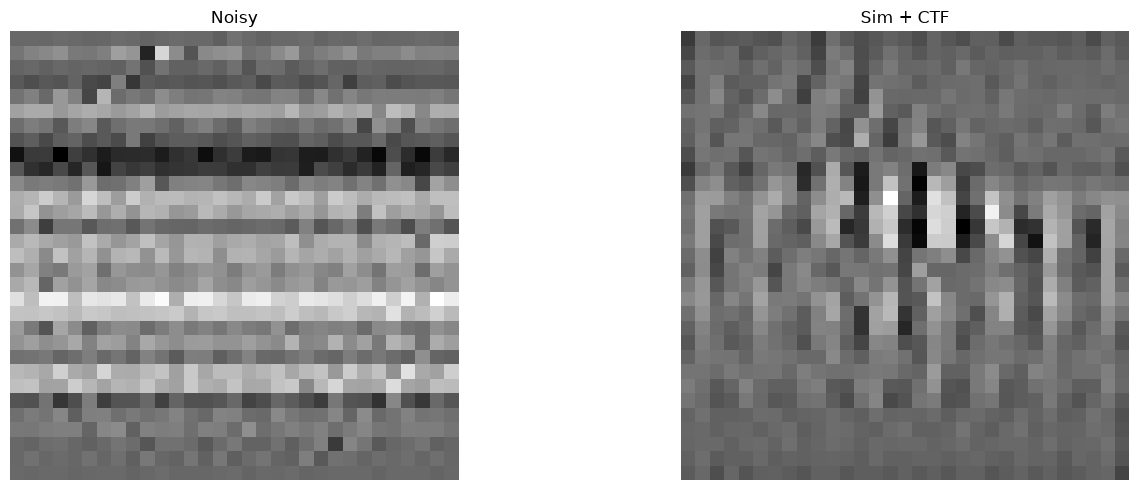

Saved NCC results to data\ncc_results.npz


In [15]:
angles = np.arange(-90, 91, 1)
R = torch.stack([rotation_matrix_y(a) for a in angles])

ncc_rib_ddw   = compare_proteins_with_NCC(rib_list,       rib_list_no_noise, r_rib, R, ctf_values)
ncc_rib_ic    = compare_proteins_with_NCC(ic_rib_list,    rib_list_no_noise, r_rib, R, ctf_values)
ncc_rib_noisy = compare_proteins_with_NCC(rib_list_noise, rib_list_no_noise, r_rib, R, ctf_values)
ncc_coh_ddw   = compare_proteins_with_NCC(coh_list,       coh_list_no_noise, r_coh, R, ctf_values)
ncc_coh_ic    = compare_proteins_with_NCC(ic_coh_list,    coh_list_no_noise, r_coh, R, ctf_values)
ncc_coh_noisy = compare_proteins_with_NCC(coh_list_noise, coh_list_no_noise, r_coh, R, ctf_values)

ncc_path = Path("data") / "ncc_results.npz"
ncc_path.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    ncc_path,
    angles=angles,
    ncc_rib_ddw=ncc_rib_ddw.detach().cpu().numpy(),
    ncc_rib_ic=ncc_rib_ic.detach().cpu().numpy(),
    ncc_rib_noisy=ncc_rib_noisy.detach().cpu().numpy(),
    ncc_coh_ddw=ncc_coh_ddw.detach().cpu().numpy(),
    ncc_coh_ic=ncc_coh_ic.detach().cpu().numpy(),
    ncc_coh_noisy=ncc_coh_noisy.detach().cpu().numpy(),
)
print(f"Saved NCC results to {ncc_path}")

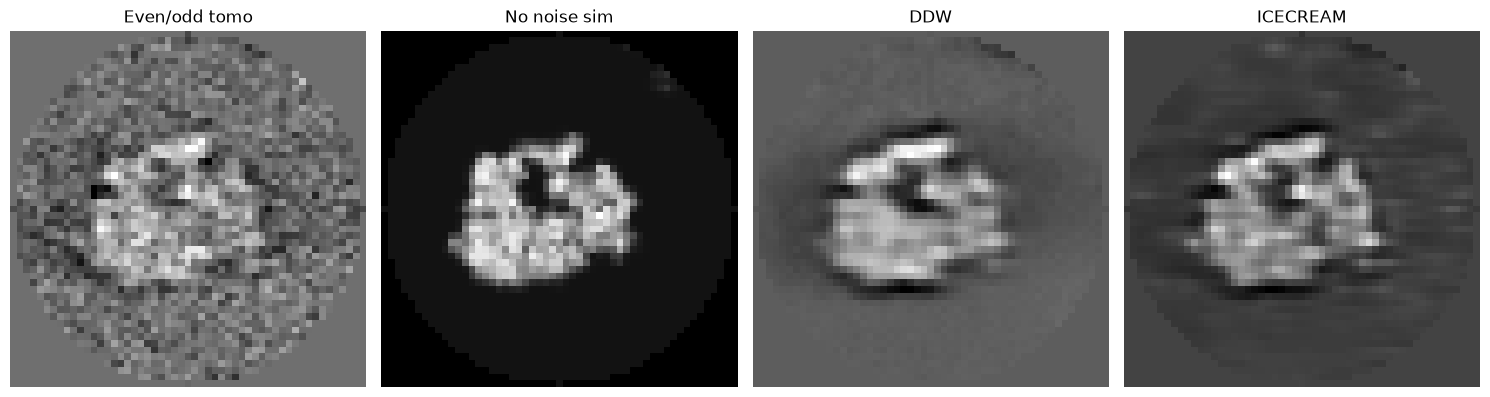

In [ ]:
n = 2

a = 26  # slice -> angle
# Create a figure with 1 row and 3 columns side-by-side
fig, axes = plt.subplots(1, 4, figsize=(15, 5))

# 1. Even/odd tomo
axes[1].imshow(rib_list_noise[n][1][a, :, :], cmap="gray")
axes[1].set_title("Even/odd tomo")
axes[1].axis("off")  # Optional: hides axis ticks for a cleaner look

# 2. Phantom tomogram protein
axes[0].imshow(rib_list_no_noise[n][1][a, :, :], cmap="gray")
axes[0].set_title("No noise sim")
axes[0].axis("off")

# 3. DDW
axes[2].imshow(rib_list[n][1][a, :, :], cmap="gray")
axes[2].set_title("DDW")
axes[2].axis("off")

# 4. ICECREAM
axes[3].imshow(ic_rib_list[n][1][a, :, :], cmap="gray")
axes[3].set_title("ICECREAM")
axes[3].axis("off")

plt.tight_layout()
plt.show()

## Particle comparison

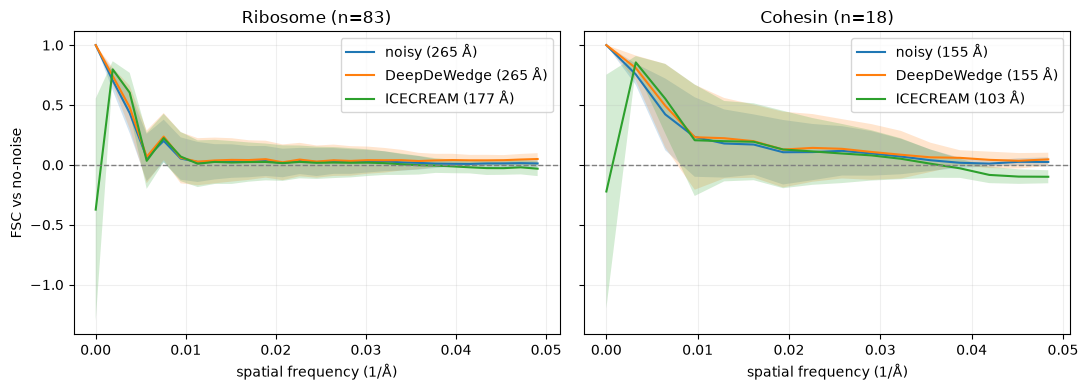

In [16]:
def soft_sphere(n, r=None, w=3):
    r = r or n // 2 - w
    c = (n - 1) / 2
    z, y, x = np.ogrid[:n, :n, :n]
    d = np.sqrt((x-c)**2 + (y-c)**2 + (z-c)**2)
    return np.clip((r + w - d) / w, 0, 1) ** 2          # 1 inside, smooth edge

def fsc(a, b):
    n = a.shape[0]
    A, B = np.fft.fftn(a), np.fft.fftn(b)
    k = np.fft.fftfreq(n)
    kx, ky, kz = np.meshgrid(k, k, k, indexing="ij")
    idx = np.round(np.sqrt(kx**2 + ky**2 + kz**2) * n).astype(int).ravel()
    s = lambda v: np.bincount(idx, v.ravel(), idx.max() + 1)[: n // 2 + 1]
    return s((A * B.conj()).real) / np.sqrt(s(abs(A)**2) * s(abs(B)**2) + 1e-12)

def mean_fsc(recon_list, gt_list, radius):
    gt = dict(gt_list); n = gt_list[0][1].shape[0]; m = soft_sphere(n, r=int(radius))
    curves = np.stack([fsc((v - v.mean()) * m, (gt[i] - gt[i].mean()) * m) for i, v in recon_list])
    return curves.mean(0), curves.std(0), n

sets = {
    "Ribosome": (rib_list_no_noise, r_rib, {"noisy": rib_list_noise, "DeepDeWedge": rib_list, "ICECREAM": ic_rib_list}),
    "Cohesin":  (coh_list_no_noise, r_coh, {"noisy": coh_list_noise, "DeepDeWedge": coh_list, "ICECREAM": ic_coh_list}),
}
pixel_size = 10.0
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, (gt, r, recons)) in zip(axes, sets.items()):
    for label, recon in recons.items():
        m, s, n = mean_fsc(recon, gt, r)
        freq = np.arange(len(m)) / (n * pixel_size)
        below = np.where(m[1:] < 0.5)[0]
        res = f"{1 / freq[below[0] + 1]:.0f} Å" if len(below) else "> Nyquist"
        ax.plot(freq, m, label=f"{label} ({res})")
        ax.fill_between(freq, m - s, m + s, alpha=0.2)
    ax.axhline(0, ls="--", c="gray", lw=1)
    ax.set_title(f"{title} (n={len(gt)})"); ax.set_xlabel("spatial frequency (1/Å)"); ax.legend()
    ax.grid(True, alpha=0.2)
axes[0].set_ylabel("FSC vs no-noise"); plt.tight_layout(); plt.show()

## Plotting data

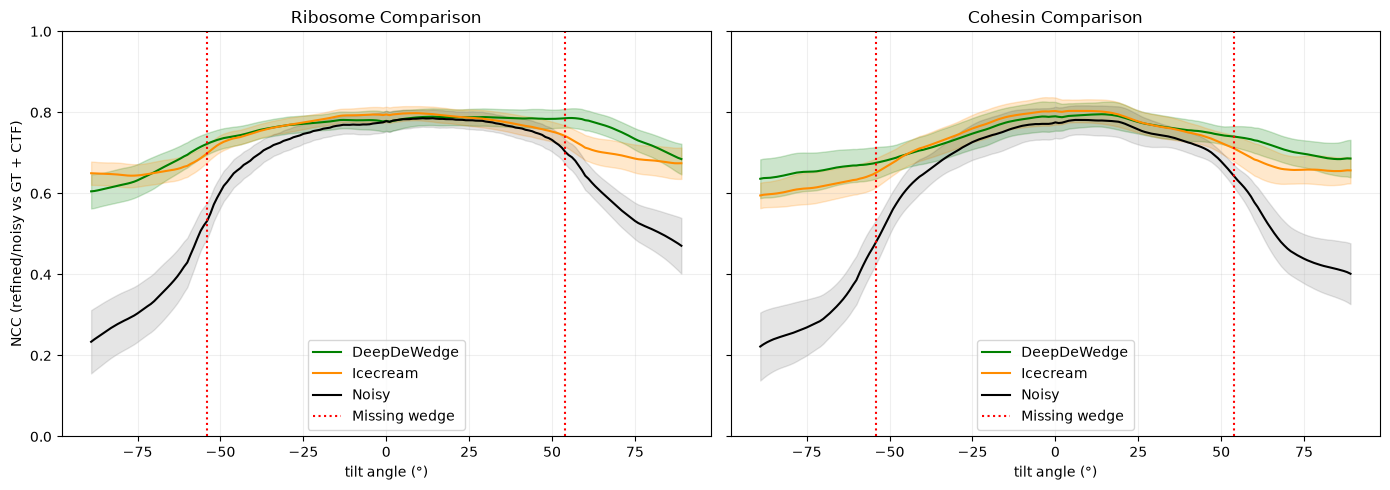

In [3]:
with np.load(Path("data") / "ncc_results.npz") as ncc_data:
    angles = ncc_data["angles"]
    ncc_rib_ddw = torch.from_numpy(ncc_data["ncc_rib_ddw"])
    ncc_rib_ic = torch.from_numpy(ncc_data["ncc_rib_ic"])
    ncc_rib_noisy = torch.from_numpy(ncc_data["ncc_rib_noisy"])
    ncc_coh_ddw = torch.from_numpy(ncc_data["ncc_coh_ddw"])
    ncc_coh_ic = torch.from_numpy(ncc_data["ncc_coh_ic"])
    ncc_coh_noisy = torch.from_numpy(ncc_data["ncc_coh_noisy"])

exclude_outer_angles = True
angle_mask = (np.abs(angles) < 90) if exclude_outer_angles else np.ones(angles.shape, dtype=bool)
angle_indices = torch.as_tensor(np.flatnonzero(angle_mask), dtype=torch.long)
x = angles[angle_mask]

# 1. Extract mean and std arrays as numpy from your PyTorch tensors
# Ribosome
y_rib_ddw = ncc_rib_ddw[:, angle_indices].mean(0).detach().cpu().numpy()
y_err_rib_ddw = ncc_rib_ddw[:, angle_indices].std(0).detach().cpu().numpy()
y_rib_ic = ncc_rib_ic[:, angle_indices].mean(0).detach().cpu().numpy()
y_err_rib_ic = ncc_rib_ic[:, angle_indices].std(0).detach().cpu().numpy()
y_rib_noisy = ncc_rib_noisy[:, angle_indices].mean(0).detach().cpu().numpy()
y_err_rib_noisy = ncc_rib_noisy[:, angle_indices].std(0).detach().cpu().numpy()

# Cohesin
y_coh_ddw = ncc_coh_ddw[:, angle_indices].mean(0).detach().cpu().numpy()
y_err_coh_ddw = ncc_coh_ddw[:, angle_indices].std(0).detach().cpu().numpy()
y_coh_ic = ncc_coh_ic[:, angle_indices].mean(0).detach().cpu().numpy()
y_err_coh_ic = ncc_coh_ic[:, angle_indices].std(0).detach().cpu().numpy()
y_coh_noisy = ncc_coh_noisy[:, angle_indices].mean(0).detach().cpu().numpy()
y_err_coh_noisy = ncc_coh_noisy[:, angle_indices].std(0).detach().cpu().numpy()

# 2. Create a figure with 2 subplots sharing the same y-axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# --- Subplot 1: Ribosome (DDW, IceCream, and Noisy) ---
ax1.plot(x, y_rib_ddw, color="g", label="DeepDeWedge")
ax1.fill_between(
    x,
    y_rib_ddw - y_err_rib_ddw,
    y_rib_ddw + y_err_rib_ddw,
    color="g",
    alpha=0.2,
)

ax1.plot(x, y_rib_ic, color="darkorange", label="Icecream")
ax1.fill_between(
    x,
    y_rib_ic - y_err_rib_ic,
    y_rib_ic + y_err_rib_ic,
    color="darkorange",
    alpha=0.2,
)

ax1.plot(
    x, y_rib_noisy, color="black", 
    # linestyle="--", 
    label="Noisy"
)
ax1.fill_between(
    x,
    y_rib_noisy - y_err_rib_noisy,
    y_rib_noisy + y_err_rib_noisy,
    color="black",
    alpha=0.1,
)

# ax1.plot(x, -np.cos(np.pi*2*x/180))

ax1.axvline(-54, color="r", linestyle=":", label="Missing wedge")
ax1.axvline(54, color="r", linestyle=":")
ax1.set_title("Ribosome Comparison")
ax1.set_xlabel("tilt angle (°)")
ax1.set_ylabel("NCC (refined/noisy vs GT + CTF)")
ax1.set_ylim(0, 1)
ax1.grid(True, alpha=0.2)
ax1.legend()


# --- Subplot 2: Cohesin (DDW, Icecream, and Noisy) ---
ax2.plot(x, y_coh_ddw, color="g", label="DeepDeWedge")
ax2.fill_between(
    x,
    y_coh_ddw - y_err_coh_ddw,
    y_coh_ddw + y_err_coh_ddw,
    color="g",
    alpha=0.2,
)

ax2.plot(x, y_coh_ic, color="darkorange", label="Icecream")
ax2.fill_between(
    x,
    y_coh_ic - y_err_coh_ic,
    y_coh_ic + y_err_coh_ic,
    color="darkorange",
    alpha=0.2,
)

ax2.plot(
    x, y_coh_noisy, color="black", 
    # linestyle="--", 
    label="Noisy"
)
ax2.fill_between(
    x,
    y_coh_noisy - y_err_coh_noisy,
    y_coh_noisy + y_err_coh_noisy,
    color="black",
    alpha=0.1,
)

ax2.axvline(-54, color="r", linestyle=":", label="Missing wedge")
ax2.axvline(54, color="r", linestyle=":")
ax2.set_title("Cohesin Comparison")
ax2.set_xlabel("tilt angle (°)")
ax2.grid(True, alpha=0.2)
ax2.legend()

plt.tight_layout()
plt.show()

## Significancy

In [29]:
import numpy as np
import math
from scipy import stats
from statsmodels.stats.multitest import multipletests

with np.load(Path("data") / "ncc_results.npz") as ncc_data:
    angles = ncc_data["angles"]
    data = {
        "ribosome": {"ddw": ncc_data["ncc_rib_ddw"], "ice": ncc_data["ncc_rib_ic"], "noisy": ncc_data["ncc_rib_noisy"]},
        "cohesin":  {"ddw": ncc_data["ncc_coh_ddw"], "ice": ncc_data["ncc_coh_ic"], "noisy": ncc_data["ncc_coh_noisy"]},
    }

exclude_outer_angles = True
valid = (np.abs(angles) < 90) if exclude_outer_angles else (np.abs(angles) <= 90)
all_ang = valid
wedge   = valid & (np.abs(angles) > 54)

def test_fisher_across_angles(x, y, mask):
    # 1. Average across the angle dimension to get one NCC value per particle
    # This leaves you with an array of shape (num_particles,)
    x_profile = x[:, mask].mean(1)
    y_profile = y[:, mask].mean(1)
    
    # 2. Safety clip
    x_profile = np.clip(x_profile, -0.9999, 0.9999)
    y_profile = np.clip(y_profile, -0.9999, 0.9999)
    
    # 3. Apply Fisher's z-transformation
    z_x = np.arctanh(x_profile)
    z_y = np.arctanh(y_profile)
    
    # 4. Perform the paired test across the angles
    p_value = stats.wilcoxon(z_x, z_y, alternative="greater").pvalue
    median_diff = np.median(x_profile - y_profile)
    
    return p_value, median_diff


rows = []
for prot, m in data.items():
    assert len({v.shape for v in m.values()}) == 1, f"{prot}: particle counts differ"
    for name, x, y, mask in [("DDW > Noisy",           "ddw", "noisy", all_ang),
                            ("ICECREAM > Noisy",      "ice", "noisy", all_ang),
                            ("DDW > ICECREAM",        "ddw", "ice",   all_ang),
                            ("DDW > ICECREAM (wedge)", "ddw", "ice",   wedge)]:
        p, d = test_fisher_across_angles(m[x], m[y], mask)
        print(f"{p:.1e}")
        rows.append((prot, name, len(m[x]), d, p))

reject, p_adj, _, _ = multipletests([r[-1] for r in rows], method="holm")
for (prot, name, n, d, p), pa, r in zip(rows, p_adj, reject):
    print(f"{prot:9s} {name:24s} n={n:3d}  median ΔNCC={d:+.3f}  p_holm={pa:.1e}  {'*' if r else 'n.s.'}")

1.3e-15
1.3e-15
4.9e-10
4.7e-12
3.8e-06
3.8e-06
5.2e-04
3.8e-05
ribosome  DDW > Noisy              n= 83  median ΔNCC=+0.112  p_holm=1.0e-14  *
ribosome  ICECREAM > Noisy         n= 83  median ΔNCC=+0.104  p_holm=1.0e-14  *
ribosome  DDW > ICECREAM           n= 83  median ΔNCC=+0.008  p_holm=2.5e-09  *
ribosome  DDW > ICECREAM (wedge)   n= 83  median ΔNCC=+0.020  p_holm=2.8e-11  *
cohesin   DDW > Noisy              n= 18  median ΔNCC=+0.131  p_holm=1.5e-05  *
cohesin   ICECREAM > Noisy         n= 18  median ΔNCC=+0.126  p_holm=1.5e-05  *
cohesin   DDW > ICECREAM           n= 18  median ΔNCC=+0.016  p_holm=5.2e-04  *
cohesin   DDW > ICECREAM (wedge)   n= 18  median ΔNCC=+0.043  p_holm=7.6e-05  *


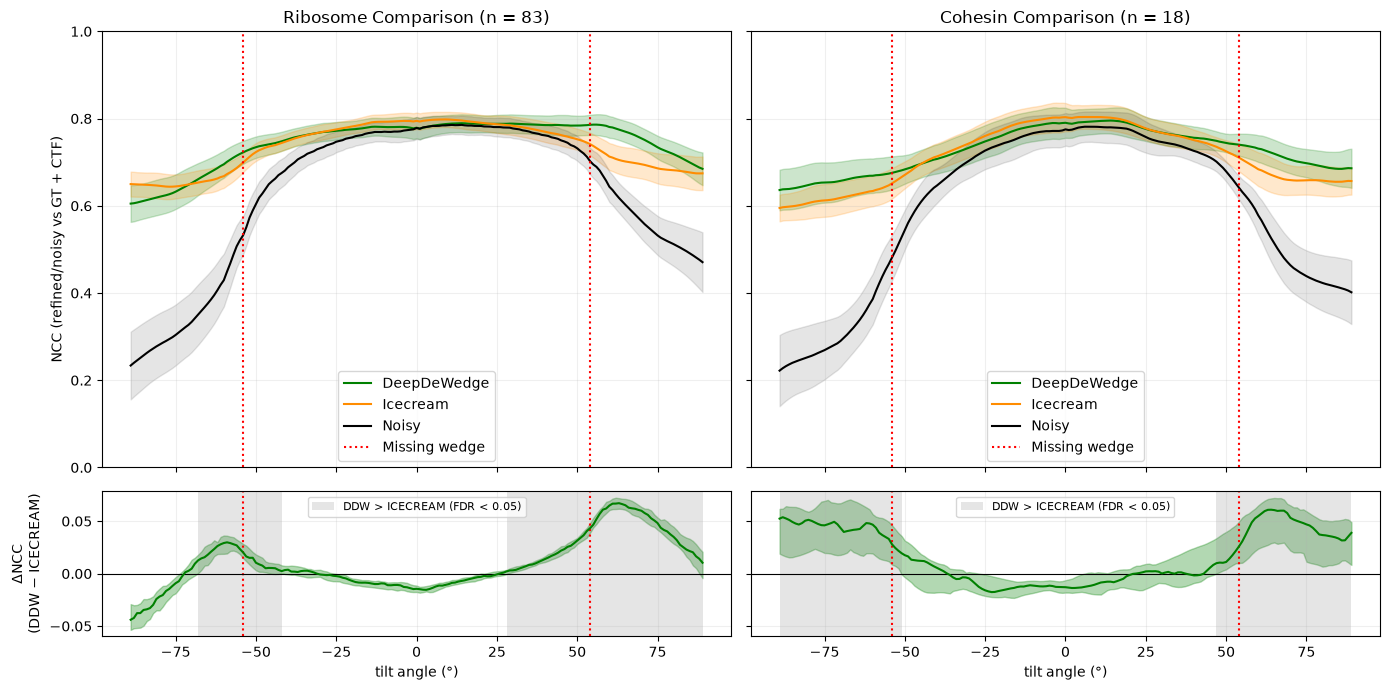

In [34]:
from pathlib import Path
 
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import wilcoxon
 
with np.load(Path("data") / "ncc_results.npz") as ncc_data:
    angles = ncc_data["angles"]
    ncc = {k: ncc_data[k] for k in ncc_data.files if k.startswith("ncc_")}
 
exclude_outer_angles = True
angle_mask = (np.abs(angles) < 90) if exclude_outer_angles else np.ones(angles.shape, dtype=bool)
x = angles[angle_mask]
 
MW = 54            # missing-wedge edge (deg)
ALPHA = 0.05
N_BOOT = 2000
rng = np.random.default_rng(42)
 
 
def bh(p):
    """Benjamini-Hochberg FDR: True where significant."""
    p = np.asarray(p)
    order = np.argsort(p)
    ranked = p[order] * len(p) / np.arange(1, len(p) + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    sig = np.empty(len(p), dtype=bool)
    sig[order] = q < ALPHA
    return sig
 
 
def paired_diff(a, b):
    """Per-angle median of a-b, bootstrap 95% CI over particles, and BH-corrected one-sided Wilcoxon."""
    d = a - b                                   # (n_particles, n_angles)
    med = np.median(d, 0)
    idx = rng.integers(0, len(d), (N_BOOT, len(d)))
    boot = np.median(d[idx], axis=1)            # (N_BOOT, n_angles)
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    p = [wilcoxon(d[:, i], alternative="greater").pvalue if np.any(d[:, i] != 0) else 1.0
         for i in range(d.shape[1])]
    return med, lo, hi, bh(p)
 
 
def plot_particle(ax, axd, name, title):
    ddw = ncc[f"ncc_{name}_ddw"][:, angle_mask]
    ic = ncc[f"ncc_{name}_ic"][:, angle_mask]
    noisy = ncc[f"ncc_{name}_noisy"][:, angle_mask]
 
    # --- top: NCC curves (mean ± std over particles) ---
    for y, color, label, a in [(ddw, "g", "DeepDeWedge", 0.2),
                               (ic, "darkorange", "Icecream", 0.2),
                               (noisy, "black", "Noisy", 0.1)]:
        m, s = y.mean(0), y.std(0)
        ax.plot(x, m, color=color, label=label)
        ax.fill_between(x, m - s, m + s, color=color, alpha=a)
    for axis in (ax, axd):
        axis.axvline(-MW, color="r", linestyle=":")
        axis.axvline(MW, color="r", linestyle=":")
        axis.grid(True, alpha=0.2)
    ax.lines[-1].set_label("Missing wedge")   # label one wedge line for the legend
    ax.set_title(f"{title} Comparison (n = {len(ddw)})")
    ax.set_ylim(0, 1)
    ax.legend(loc="lower center")
 
    # --- bottom: paired difference DDW - ICECREAM ---
    med, lo, hi, sig = paired_diff(ddw, ic)
    axd.axhline(0, color="k", lw=0.8)
    axd.plot(x, med, color="g")
    axd.fill_between(x, lo, hi, color="g", alpha=0.3)
    axd.fill_between(x, 0, 1, where=sig, transform=axd.get_xaxis_transform(),
                     color="grey", alpha=0.2, lw=0, label=f"DDW > ICECREAM (FDR < {ALPHA})")
    axd.set_xlabel("tilt angle (°)")
    axd.legend(loc="upper center", fontsize=8)
 
 
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True, sharey="row",
                         gridspec_kw={"height_ratios": [3, 1]})
plot_particle(axes[0, 0], axes[1, 0], "rib", "Ribosome")
plot_particle(axes[0, 1], axes[1, 1], "coh", "Cohesin")
axes[0, 0].set_ylabel("NCC (refined/noisy vs GT + CTF)")
axes[1, 0].set_ylabel("ΔNCC\n(DDW − ICECREAM)")
 
plt.tight_layout()
plt.show()
 

### FRC vs angles

In [39]:
def soft_circular_mask(n, radius, edge_width):
    """Circular mask of 1 inside `radius`, falling to 0 over `edge_width` pixels with a cosine edge."""
    center = (n - 1) / 2
    y, x = np.mgrid[:n, :n]
    r = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    mask = np.zeros((n, n))
    mask[r <= radius] = 1
    edge = (r > radius) & (r < radius + edge_width)
    mask[edge] = 0.5 * (1 + np.cos(np.pi * (r[edge] - radius) / edge_width))
    return mask
 
def apply_mask(img, mask):
    """Subtract the mean inside the mask, then apply the mask."""
    mean = np.sum(img * mask) / np.sum(mask)
    return (img - mean) * mask

def ring_sums(img1, img2):

    """Per-ring sums of the cross-power and both power spectra of two square 2D images.
 
    Returns (spatial frequency in cycles/pixel, cross, power1, power2) for rings up to Nyquist.

    """

    assert img1.shape == img2.shape and img1.shape[0] == img1.shape[1]

    n = img1.shape[0]
 
    f1 = np.fft.fftshift(np.fft.fft2(img1))

    f2 = np.fft.fftshift(np.fft.fft2(img2))
 
    # Integer ring index for each Fourier pixel

    freq = np.fft.fftshift(np.fft.fftfreq(n)) * n

    ky, kx = np.meshgrid(freq, freq, indexing="ij")

    r = np.round(np.sqrt(kx**2 + ky**2)).astype(int).ravel()
 
    n_rings = n // 2 + 1  # up to and including Nyquist

    cross = np.bincount(r, weights=(f1 * np.conj(f2)).real.ravel(), minlength=n_rings)

    p1 = np.bincount(r, weights=(np.abs(f1) ** 2).ravel(), minlength=n_rings)

    p2 = np.bincount(r, weights=(np.abs(f2) ** 2).ravel(), minlength=n_rings)
 
    spatial_freq = np.arange(n_rings) / n

    return spatial_freq, cross[:n_rings], p1[:n_rings], p2[:n_rings]
 
 
def fourier_ring_correlation(img1, img2, mask=None):

    """FRC between two square 2D images, optionally masked first."""

    if mask is not None:

        img1, img2 = apply_mask(img1, mask), apply_mask(img2, mask)

    spatial_freq, cross, p1, p2 = ring_sums(img1, img2)

    return spatial_freq, cross / np.sqrt(p1 * p2)

def pooled_fourier_ring_correlation(stack1, stack2, mask=None):

    """FRC with ring sums pooled over all slice pairs of two stacks before normalizing."""

    cross = p1 = p2 = 0

    for img1, img2 in zip(stack1, stack2):

        if mask is not None:

            img1, img2 = apply_mask(img1, mask), apply_mask(img2, mask)

        spatial_freq, c_i, p1_i, p2_i = ring_sums(img1, img2)

        cross, p1, p2 = cross + c_i, p1 + p1_i, p2 + p2_i

    return spatial_freq, cross / np.sqrt(p1 * p2)

In [87]:
import numpy as np
import torch

from torch_fourier_slice import project_3d_to_2d

angles = np.arange(-90, 91, 1)
R = torch.stack([rotation_matrix_y(a) for a in angles])

n_bins = 15
edges = np.linspace(0, 0.5, n_bins+1)  # 0, 0.05, ..., 0.5
FRC_windows = [[edges[k], edges[k + 1]] for k in range(n_bins)]

def unpack_volume_list(volume_list):
    """
    Convert each item to a 3D array.
    Handles both:
      - raw volume arrays: volume
      - tuple entries: (label, volume)
    """
    volumes = []
    for item in volume_list:
        if isinstance(item, tuple):
            if len(item) != 2:
                raise ValueError(f"Tuple entry has unexpected length: {len(item)}")
            _, vol = item
        else:
            vol = item

        v = np.asarray(vol, dtype=np.float32)
        if v.ndim != 3:
            raise ValueError(f"Each volume must be 3D, got shape {v.shape}")
        volumes.append(v)

    return volumes

def project_all_volumes(volumes, rotation_matrices):
    """
    volumes: list of 3D arrays, each shape (D, D, D)
    returns: torch.Tensor of shape (n_volumes, n_angles, H, W)
    """
    proj = []
    for vol in volumes:
        v = torch.as_tensor(vol, dtype=torch.float32)
        proj.append(project_3d_to_2d(v, rotation_matrices))
    return torch.stack(proj)

def compute_frc_window(freqs, frc_values, window, end_inclusive=False):
    start, end = window
    if end_inclusive:
        mask = (freqs >= start) & (freqs <= end)
    else:
        mask = (freqs >= start) & (freqs < end)
    return np.mean(frc_values[mask]) if np.any(mask) else np.nan

# Unpack the actual 3D volumes from the tuple structure
rib_vols = unpack_volume_list(coh_list)
ice_vols = unpack_volume_list(ic_coh_list)
gt_vols = unpack_volume_list(coh_list_no_noise)
noisy_vols = unpack_volume_list(coh_list_noise)

# Project all volumes for all angles
projections_ddw = project_all_volumes(rib_vols, R)
projections_ice = project_all_volumes(ice_vols, R)
projections_gt = project_all_volumes(gt_vols, R)
projections_noisy = project_all_volumes(noisy_vols, R)

# Sanity check
print("projections_ddw:", projections_ddw.shape)
print("projections_ice:", projections_ice.shape)
print("projections_gt:", projections_gt.shape)
print("projections_noisy:", projections_noisy.shape)

# FRC heatmaps
FRC_heatmap_ddw = np.zeros((len(angles), len(FRC_windows)))
FRC_heatmap_ice = np.zeros((len(angles), len(FRC_windows)))

n_particles = len(rib_vols)

for i in range(len(angles)):
    # stack all particles for this angle
    stack_ddw = projections_ddw[:, i].detach().cpu().numpy()   # (n_particles, H, W)
    stack_ice = projections_ice[:, i].detach().cpu().numpy()   # (n_particles, H, W)
    stack_gt = projections_gt[:, i].detach().cpu().numpy()     # (n_particles, H, W)
    stack_noisy = projections_noisy[:, i].detach().cpu().numpy()  # (n_particles, H, W)

    # pooled FRC against ground truth
    spatial_freq, frc_ddw = pooled_fourier_ring_correlation(stack_ddw, stack_gt)
    spatial_freq, frc_ice = pooled_fourier_ring_correlation(stack_ice, stack_gt)
    spatial_freq, frc_noisy = pooled_fourier_ring_correlation(stack_noisy, stack_gt)

    for j, window in enumerate(FRC_windows):
        if j == len(FRC_windows) - 1:
            # last window includes the endpoint
            noisy_frc = compute_frc_window(spatial_freq, frc_noisy, window, end_inclusive=True)
            ddw_frc = compute_frc_window(spatial_freq, frc_ddw, window, end_inclusive=True)
            ice_frc = compute_frc_window(spatial_freq, frc_ice, window, end_inclusive=True)
        else:
            noisy_frc = compute_frc_window(spatial_freq, frc_noisy, window)
            ddw_frc = compute_frc_window(spatial_freq, frc_ddw, window)
            ice_frc = compute_frc_window(spatial_freq, frc_ice, window)

        FRC_heatmap_ddw[i, j] = ddw_frc - noisy_frc
        FRC_heatmap_ice[i, j] = ice_frc - noisy_frc

print("FRC_heatmap_ddw shape:", FRC_heatmap_ddw.shape)
print("FRC_heatmap_ice shape:", FRC_heatmap_ice.shape)

projections_ddw: torch.Size([18, 181, 31, 31])
projections_ice: torch.Size([18, 181, 31, 31])
projections_gt: torch.Size([18, 181, 31, 31])
projections_noisy: torch.Size([18, 181, 31, 31])
FRC_heatmap_ddw shape: (181, 15)
FRC_heatmap_ice shape: (181, 15)


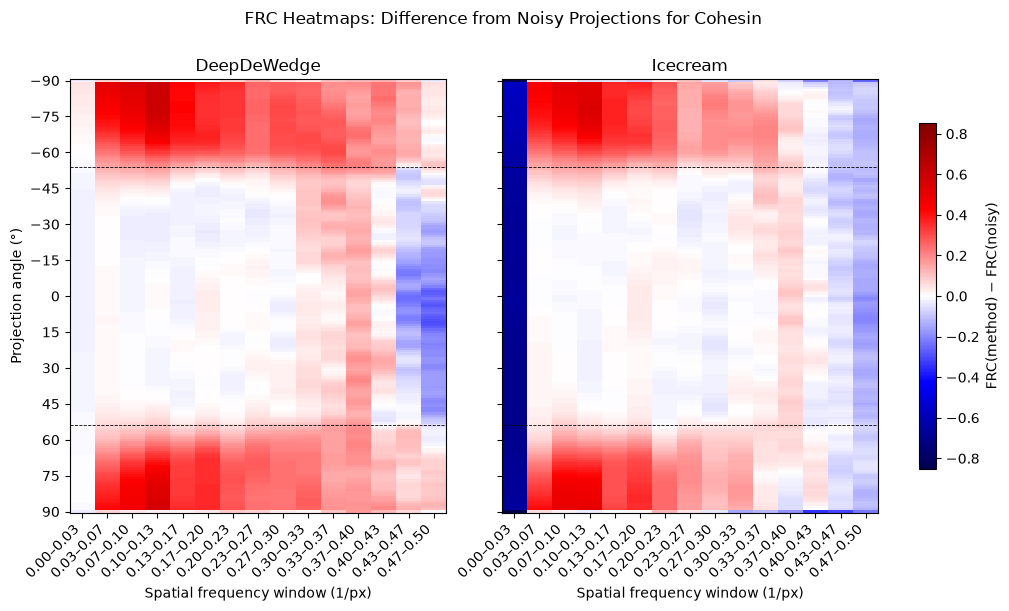

In [88]:
from matplotlib.colors import TwoSlopeNorm

window_labels = [f"{edges[k]:.2f}–{edges[k+1]:.2f}" for k in range(len(edges) - 1)]
lim = np.nanmax(np.abs([FRC_heatmap_ddw, FRC_heatmap_ice]))
norm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
extent = [-0.5, len(window_labels) - 0.5, angles[-1] + 0.5, angles[0] - 0.5]

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True, layout="constrained")
fig.suptitle("FRC Heatmaps: Difference from Noisy Projections for Cohesin \n")
for ax, data, title in zip(axes, [FRC_heatmap_ddw, FRC_heatmap_ice], ["DeepDeWedge", "Icecream"]):
    im = ax.imshow(data, cmap="seismic", norm=norm, aspect="auto",
                   extent=extent, interpolation="nearest")
    ax.set_title(title)
    ax.set_xticks(np.arange(len(window_labels)))
    ax.set_xticklabels(window_labels, rotation=45, ha="right")
    ax.set_xlabel("Spatial frequency window (1/px)")
    for a in (-54, 54):  # mark training / quasi-GT tilt limits
        ax.axhline(a, color="k", lw=0.6, ls="--")
axes[0].set_yticks(np.arange(-90, 91, 15))
axes[0].set_ylabel("Projection angle (°)")
fig.colorbar(im, ax=axes, label="FRC(method) − FRC(noisy)", shrink=0.8)
plt.show()

## Tubulin + proteasome analysis

Tubulin Napari viewer ready; use the layer checkboxes to compare the four reconstructions.
tubulin: analysed 17 particles {'Noisy': 17, 'DDW': 17, 'ICECREAM': 17}; skipped 3 at tomogram boundaries; crop radius 36 voxels.
proteasome: analysed 170 particles {'Noisy': 170, 'DDW': 170, 'ICECREAM': 170}; skipped 10 at tomogram boundaries; crop radius 12 voxels.


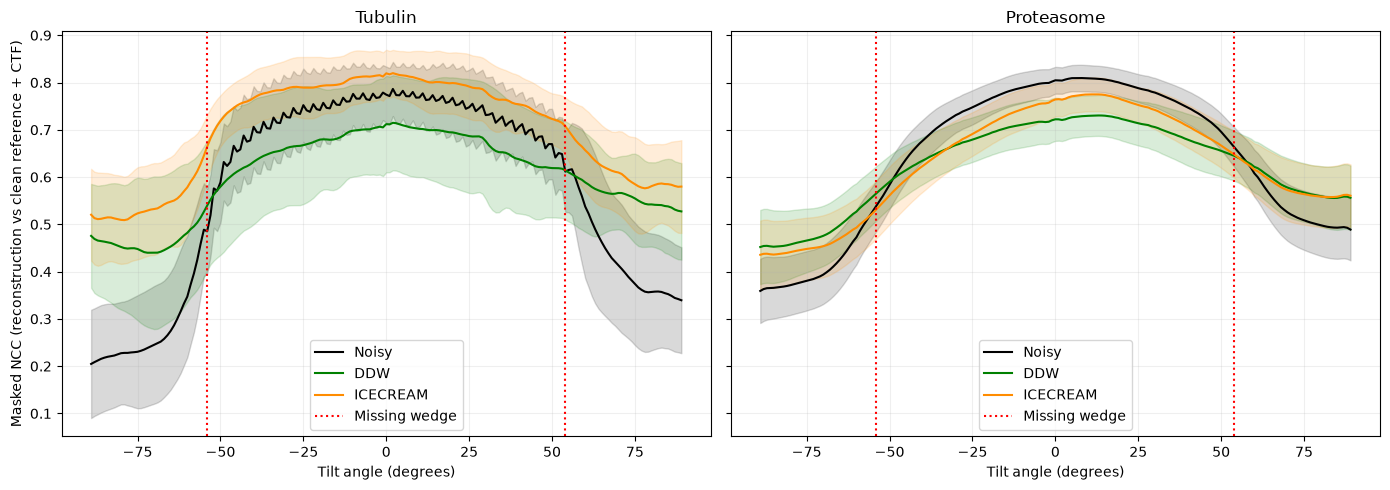

tubulin    DDW > Noisy              n= 17 median delta NCC=+0.020 p_holm=3.61e-01 n.s.
tubulin    ICECREAM > Noisy         n= 17 median delta NCC=+0.137 p_holm=5.34e-05 *
tubulin    DDW > ICECREAM           n= 17 median delta NCC=-0.091 p_holm=1.00e+00 n.s.
tubulin    DDW > ICECREAM (wedge)   n= 17 median delta NCC=-0.046 p_holm=1.00e+00 n.s.
proteasome DDW > Noisy              n=170 median delta NCC=-0.013 p_holm=1.00e+00 n.s.
proteasome ICECREAM > Noisy         n=170 median delta NCC=-0.005 p_holm=1.00e+00 n.s.
proteasome DDW > ICECREAM           n=170 median delta NCC=-0.005 p_holm=1.00e+00 n.s.
proteasome DDW > ICECREAM (wedge)   n=170 median delta NCC=+0.015 p_holm=9.61e-07 *
Saved angle-wise NCC results: C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\phantom_tomogram_29_10\tubulin_proteasome_ncc_29_10.npz
Saved summary: C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\phantom_tomogram_29_10\tubulin_protea

In [3]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import mrcfile
import numpy as np
import napari
import pandas as pd
import torch
import torch.nn.functional as F
from scipy import stats
from statsmodels.stats.multitest import multipletests
from torch_ctf import calculate_ctf_2d
from torch_fourier_slice import project_3d_to_2d
from torch_grid_utils import fftfreq_grid

base_path = Path(r"C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\phantom_tomogram_29_10")
protein_data = pd.read_csv(base_path / "protein_data.csv")
required_columns = {"protein_name", "subtomo_id", "sub_loc"}
missing_columns = required_columns.difference(protein_data.columns)
if missing_columns:
    raise ValueError(f"protein_data.csv is missing columns: {sorted(missing_columns)}")

protein_names = ("tubulin", "proteasome")
crop_radii = {"tubulin": 36, "proteasome": 12}
subtomo_ids = sorted(protein_data["subtomo_id"].astype(int).unique())
if subtomo_ids != [0, 1, 2, 3]:
    raise ValueError(f"Expected four sub-tomograms (ids 0-3), found {subtomo_ids}")


def _mrc_tensor(path):
    if not path.is_file():
        raise FileNotFoundError(f"Required tomogram not found: {path}")
    with mrcfile.open(path) as mrc:
        return torch.from_numpy(np.array(mrc.data, dtype=np.float32, copy=True))


def _parse_center(value):
    values = re.findall(r"-?\d+", str(value).replace("np.int64", ""))
    if len(values) != 3:
        raise ValueError(f"Expected an (x, y, z) center, got {value!r}")
    return tuple(map(int, values))


def _crop_particle(volume, center_xyz, radius, spherical=True):
    x, y, z = center_xyz
    z_size, y_size, x_size = volume.shape
    if (x - radius < 0 or x + radius >= x_size or
            y - radius < 0 or y + radius >= y_size or
            z - radius < 0 or z + radius >= z_size):
        return None
    crop = volume[z - radius:z + radius + 1,
                  y - radius:y + radius + 1,
                  x - radius:x + radius + 1].clone()
    if spherical:
        zz, yy, xx = np.ogrid[-radius:radius + 1, -radius:radius + 1, -radius:radius + 1]
        crop[torch.from_numpy(zz**2 + yy**2 + xx**2 > radius**2)] = 0
    return crop


def _rectangular_projection_mask(support_volume, rotation_matrices, margin=2):
    support_projections = project_3d_to_2d(
        support_volume, rotation_matrices=rotation_matrices
    )
    masks = torch.zeros_like(support_projections, dtype=torch.float32)
    height, width = support_projections.shape[-2:]
    for angle_index, projection in enumerate(support_projections):
        foreground = torch.nonzero(projection > 0)
        if foreground.numel() == 0:
            raise ValueError(f"Tubulin support is empty at angle index {angle_index}")
        y_min, x_min = foreground.min(dim=0).values.tolist()
        y_max, x_max = foreground.max(dim=0).values.tolist()
        y_min, x_min = max(0, y_min - margin), max(0, x_min - margin)
        y_max, x_max = min(height, y_max + margin + 1), min(width, x_max + margin + 1)
        masks[angle_index, y_min:y_max, x_min:x_max] = 1
    return masks


def _rotation_y(angle_deg):
    theta = torch.deg2rad(torch.tensor(float(angle_deg)))
    cosine, sine = torch.cos(theta), torch.sin(theta)
    zero, one = torch.tensor(0.0), torch.tensor(1.0)
    return torch.stack((
        torch.stack((cosine, zero, sine)),
        torch.stack((zero, one, zero)),
        torch.stack((-sine, zero, cosine)),
    ))


def _apply_abs_ctf(images, ctf_values, pad):
    height, width = images.shape[-2:]
    padded = F.pad(images, (pad, pad, pad, pad), mode="reflect") if pad else images
    padded_height, padded_width = padded.shape[-2:]
    ctf = calculate_ctf_2d(
        **{**ctf_values, "rfft": True, "fftshift": False},
        image_shape=(padded_height, padded_width),
    )
    frequency = fftfreq_grid(
        image_shape=(padded_height, padded_width), rfft=True, fftshift=False, norm=True
    )
    ctf[frequency > 0.5] = 0
    filtered = torch.fft.irfft2(
        torch.fft.rfft2(padded) * torch.abs(ctf), s=(padded_height, padded_width)
    )
    return filtered[..., pad:pad + height, pad:pad + width] if pad else filtered


def _masked_ncc(first, second, mask):
    weights = mask / mask.sum(dim=(-2, -1), keepdim=True)
    first = first - (first * weights).sum(dim=(-2, -1), keepdim=True)
    second = second - (second * weights).sum(dim=(-2, -1), keepdim=True)
    numerator = (mask * first * second).sum(dim=(-2, -1))
    denominator = torch.sqrt(
        (mask * first.square()).sum(dim=(-2, -1)) *
        (mask * second.square()).sum(dim=(-2, -1))
    ).clamp_min(torch.finfo(first.dtype).eps)
    return numerator / denominator


angles = np.arange(-90, 91, 1)
rotation_matrices = torch.stack([_rotation_y(angle) for angle in angles])
ctf_values = {
    "defocus": 3,
    "astigmatism": 0.0,
    "astigmatism_angle": 0.0,
    "voltage": 300,
    "spherical_aberration": 2.7,
    "amplitude_contrast": 0.07,
    "phase_shift": 0.0,
    "pixel_size": 10.0,
    "rfft": True,
    "fftshift": False,
    "beam_tilt_mrad": None,
    "even_zernike_coeffs": None,
    "odd_zernike_coeffs": None,
    "transform_matrix": None,
    "return_complex_ctf": False,
}

variant_paths = {
    "Noisy": lambda i: (
        base_path / f"even/noisy_phantom_tomo_id{i}_even.mrc",
        base_path / f"odd/noisy_phantom_tomo_id{i}_odd.mrc",
    ),
    "DDW": lambda i: (
        base_path / f"ddw/noisy_phantom_tomo_id{i}_even+noisy_phantom_tomo_id{i}_odd_refined.mrc",
    ),
    "ICECREAM": lambda i: (
        base_path / f"icecream/noisy_phantom_tomo_id{i}_even_noisy_phantom_tomo_id{i}_odd_icecream.mrc",
    ),
}
clean_paths = {i: base_path / f"no_noise/no_noise_phantom_tomo_id{i}.mrc" for i in subtomo_ids}
for path in clean_paths.values():
    if not path.is_file():
        raise FileNotFoundError(f"Required clean reference tomogram not found: {path}")

available_variants = ["Noisy"]
for variant in ("DDW", "ICECREAM"):
    paths_by_id = {i: variant_paths[variant](i) for i in subtomo_ids}
    present = [all(path.is_file() for path in paths) for paths in paths_by_id.values()]
    if any(present) and not all(present):
        missing = [str(path) for paths in paths_by_id.values()
                   for path in paths if not path.is_file()]
        raise FileNotFoundError(f"Incomplete {variant} tomograms; missing: {missing}")
    if all(present):
        available_variants.append(variant)
    else:
        print(f"{variant} outputs not found for 29_10; skipping this comparison for now.")

ncc_lists = {protein: {variant: [] for variant in available_variants}
             for protein in protein_names}
particle_ids = {protein: [] for protein in protein_names}
subtomo_for_particle = {protein: [] for protein in protein_names}
skipped_particles = {protein: 0 for protein in protein_names}
tubulin_viewer_crops = {}
tubulin_viewer_particle = None

for subtomo_id in subtomo_ids:
    clean_volume = _mrc_tensor(clean_paths[subtomo_id])
    volumes = {"Ground truth": clean_volume}
    even_path, odd_path = variant_paths["Noisy"](subtomo_id)
    even_volume = _mrc_tensor(even_path)
    odd_volume = _mrc_tensor(odd_path)
    if even_volume.shape != clean_volume.shape or odd_volume.shape != clean_volume.shape:
        raise ValueError(f"Noisy and clean tomogram shapes differ for subtomo {subtomo_id}")
    volumes["Noisy"] = (even_volume + odd_volume) / 2
    del even_volume, odd_volume

    for variant in available_variants:
        if variant == "Noisy":
            continue
        volumes[variant] = _mrc_tensor(variant_paths[variant](subtomo_id)[0])
        if volumes[variant].shape != clean_volume.shape:
            raise ValueError(f"{variant} and clean tomogram shapes differ for subtomo {subtomo_id}")

    rows = protein_data[protein_data["subtomo_id"].astype(int) == subtomo_id]
    for row_index, row in rows.iterrows():
        protein = str(row["protein_name"]).strip().lower()
        if protein not in protein_names:
            continue
        radius = crop_radii[protein]
        center_xyz = _parse_center(row["sub_loc"])
        spherical_crop = protein != "tubulin"
        clean_crop = _crop_particle(clean_volume, center_xyz, radius, spherical=spherical_crop)
        if clean_crop is None:
            skipped_particles[protein] += 1
            continue
        is_viewer_particle = protein == "tubulin" and tubulin_viewer_particle is None
        if is_viewer_particle:
            tubulin_viewer_particle = (subtomo_id, int(row_index))
            tubulin_viewer_crops["No noise"] = clean_crop.detach().cpu().numpy()

        clean_projection = project_3d_to_2d(clean_crop, rotation_matrices=rotation_matrices)
        clean_ctf = _apply_abs_ctf(clean_projection, ctf_values, pad=clean_projection.shape[-1] // 2)
        if protein == "tubulin":
            support_threshold = clean_crop.abs().max() * 0.05
            support_volume = (clean_crop.abs() > support_threshold).float()
            mask = _rectangular_projection_mask(support_volume, rotation_matrices)
        else:
            yy = torch.arange(clean_projection.shape[-2]) - (clean_projection.shape[-2] - 1) / 2
            xx = torch.arange(clean_projection.shape[-1]) - (clean_projection.shape[-1] - 1) / 2
            mask = (yy[:, None].square() + xx[None, :].square() <= radius**2).float()

        for variant in available_variants:
            particle_crop = _crop_particle(
                volumes[variant], center_xyz, radius, spherical=spherical_crop
            )
            if particle_crop is None:
                raise RuntimeError(f"Particle crop missing in {variant} for row {row_index}")
            if is_viewer_particle:
                layer_name = "Noise" if variant == "Noisy" else variant
                tubulin_viewer_crops[layer_name] = particle_crop.detach().cpu().numpy()
            projection = project_3d_to_2d(particle_crop, rotation_matrices=rotation_matrices)
            particle_ncc = _masked_ncc(projection, clean_ctf, mask)
            ncc_lists[protein][variant].append(particle_ncc.detach().cpu().numpy())

        particle_ids[protein].append(int(row_index))
        subtomo_for_particle[protein].append(subtomo_id)
    del volumes, clean_volume

viewer_layer_order = ("No noise", "Noise", "DDW", "ICECREAM")
missing_viewer_layers = set(viewer_layer_order).difference(tubulin_viewer_crops)
if missing_viewer_layers:
    print(f"Cannot create the full Tubulin Napari viewer; missing layers: {sorted(missing_viewer_layers)}")
else:
    viewer_values = np.concatenate([
        tubulin_viewer_crops[name].ravel() for name in viewer_layer_order
    ])
    contrast_limits = tuple(np.percentile(viewer_values, [1, 99]))
    viewer = napari.Viewer(
        title=f"Tubulin particle: subtomogram {tubulin_viewer_particle[0]}, row {tubulin_viewer_particle[1]}"
    )
    for layer_name in viewer_layer_order:
        viewer.add_image(
            tubulin_viewer_crops[layer_name],
            name=layer_name,
            colormap="gray",
            contrast_limits=contrast_limits,
            scale=(10.0, 10.0, 10.0),
            visible=layer_name == "No noise",
        )
    print("Tubulin Napari viewer ready; use the layer checkboxes to compare the four reconstructions.")

for protein in protein_names:
    if not particle_ids[protein]:
        raise ValueError(f"No in-bounds {protein} particles were available to analyse")

ncc_results = {
    protein: {variant: np.stack(values) for variant, values in ncc_lists[protein].items()}
    for protein in protein_names
}
for protein in protein_names:
    counts = {variant: values.shape[0] for variant, values in ncc_results[protein].items()}
    print(f"{protein}: analysed {len(particle_ids[protein])} particles {counts}; "
          f"skipped {skipped_particles[protein]} at tomogram boundaries; "
          f"crop radius {crop_radii[protein]} voxels.")

colors = {"Noisy": "black", "DDW": "green", "ICECREAM": "darkorange"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
angle_mask = np.abs(angles) < 90
for ax, protein in zip(axes, protein_names):
    for variant in available_variants:
        values = ncc_results[protein][variant][:, angle_mask]
        mean = np.nanmean(values, axis=0)
        spread = np.nanstd(values, axis=0, ddof=1) if values.shape[0] > 1 else np.zeros_like(mean)
        ax.plot(angles[angle_mask], mean, color=colors[variant], label=variant)
        ax.fill_between(angles[angle_mask], mean - spread, mean + spread,
                        color=colors[variant], alpha=0.15)
    ax.axvline(-54, color="red", linestyle=":", label="Missing wedge")
    ax.axvline(54, color="red", linestyle=":")
    ax.set_title(protein.capitalize())
    ax.set_xlabel("Tilt angle (degrees)")
    ax.grid(True, alpha=0.2)
    ax.legend()
axes[0].set_ylabel("Masked NCC (reconstruction vs clean reference + CTF)")
fig.tight_layout()
plot_path = base_path / "tubulin_proteasome_ncc_29_10.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

all_angles = np.abs(angles) < 90
wedge_angles = all_angles & (np.abs(angles) > 54)
comparisons = [("DDW > Noisy", "DDW", "Noisy", all_angles),
               ("ICECREAM > Noisy", "ICECREAM", "Noisy", all_angles)]
if "DDW" in available_variants and "ICECREAM" in available_variants:
    comparisons.extend([
        ("DDW > ICECREAM", "DDW", "ICECREAM", all_angles),
        ("DDW > ICECREAM (wedge)", "DDW", "ICECREAM", wedge_angles),
    ])

stat_rows = []
for protein in protein_names:
    for label, first_name, second_name, selected_angles in comparisons:
        if first_name not in available_variants or second_name not in available_variants:
            continue
        first, second = ncc_results[protein][first_name], ncc_results[protein][second_name]
        if first.shape != second.shape:
            raise ValueError(f"Particle/angle mismatch for {protein}: {first_name} vs {second_name}")
        first_profile = np.clip(first[:, selected_angles].mean(axis=1), -0.9999, 0.9999)
        second_profile = np.clip(second[:, selected_angles].mean(axis=1), -0.9999, 0.9999)
        p_value = 1.0 if np.allclose(first_profile, second_profile) else stats.wilcoxon(
            np.arctanh(first_profile), np.arctanh(second_profile), alternative="greater"
        ).pvalue
        stat_rows.append({
            "protein": protein, "comparison": label, "n_particles": len(first_profile),
            "median_delta_ncc": float(np.median(first_profile - second_profile)),
            "p_value": float(p_value),
        })

if stat_rows:
    rejected, adjusted_p, _, _ = multipletests([row["p_value"] for row in stat_rows], method="holm")
    for row, p_adjusted, significant in zip(stat_rows, adjusted_p, rejected):
        row["p_holm"] = float(p_adjusted)
        row["significant"] = bool(significant)
        print(f"{row['protein']:10s} {row['comparison']:24s} n={row['n_particles']:3d} "
              f"median delta NCC={row['median_delta_ncc']:+.3f} "
              f"p_holm={row['p_holm']:.2e} {'*' if significant else 'n.s.'}")
else:
    print("No DDW/ICECREAM statistical comparisons available yet.")

summary_rows = []
for protein in protein_names:
    for variant in available_variants:
        per_particle = ncc_results[protein][variant][:, angle_mask].mean(axis=1)
        summary_rows.append({
            "protein": protein, "variant": variant, "n_particles": len(per_particle),
            "mean_ncc": float(np.mean(per_particle)),
            "std_ncc": float(np.std(per_particle, ddof=1)) if len(per_particle) > 1 else 0.0,
        })

result_payload = {"angles": angles}
for protein in protein_names:
    result_payload[f"particle_ids_{protein}"] = np.asarray(particle_ids[protein], dtype=int)
    result_payload[f"subtomo_ids_{protein}"] = np.asarray(subtomo_for_particle[protein], dtype=int)
    result_payload[f"crop_radius_{protein}"] = np.asarray(crop_radii[protein])
    for variant in available_variants:
        result_payload[f"ncc_{protein}_{variant.lower()}"] = ncc_results[protein][variant]

npz_path = base_path / "tubulin_proteasome_ncc_29_10.npz"
summary_path = base_path / "tubulin_proteasome_ncc_summary_29_10.csv"
stats_path = base_path / "tubulin_proteasome_ncc_statistics_29_10.csv"
np.savez_compressed(npz_path, **result_payload)
pd.DataFrame(summary_rows).to_csv(summary_path, index=False)
pd.DataFrame(stat_rows).to_csv(stats_path, index=False)
print(f"Saved angle-wise NCC results: {npz_path}")
print(f"Saved summary: {summary_path}")
print(f"Saved paired statistics: {stats_path}")
print(f"Saved plot: {plot_path}")

## Icecream full cover simulation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import time

@njit
def run_single_fill_simulation(x, y, z, sub_size, max_steps):
    """
    Simulates placing random sub-cubes until every voxel in the volume is zeroed out.
    Returns the exact step count where voxels_remaining reaches 0.
    """
    total_voxels = x * y * z
    # 1 = unchecked, 0 = checked (filled)
    grid = np.ones(total_voxels, dtype=np.uint8)
    voxels_remaining = total_voxels
    
    x_max = x - sub_size
    y_max = y - sub_size
    z_max = z - sub_size
    
    for step in range(1, max_steps + 1):
        # Sample top-left-front corner of the sub-cube
        x0 = np.random.randint(0, x_max + 1)
        y0 = np.random.randint(0, y_max + 1)
        z0 = np.random.randint(0, z_max + 1)
        
        # Zero out voxels inside the sub-cube
        for xi in range(x0, x0 + sub_size):
            x_offset = xi * (y * z)
            for yi in range(y0, y0 + sub_size):
                y_offset = x_offset + yi * z
                for zi in range(z0, z0 + sub_size):
                    idx = y_offset + zi
                    if grid[idx] == 1:
                        grid[idx] = 0
                        voxels_remaining -= 1
        
        # Stop as soon as every voxel is cleared
        if voxels_remaining == 0:
            return step
            
    return max_steps

def run_monte_carlo(n_trials=30, max_steps=700000):
    x, y, z = 512, 512, 100
    sub_size = 64
    
    print("Warming up Numba compiler...")
    _ = run_single_fill_simulation(x, y, z, sub_size, max_steps)
    
    results = []
    print(f"Running {n_trials} trials (max steps: {max_steps})...")
    start_time = time.time()
    
    for trial in range(n_trials):
        steps = run_single_fill_simulation(x, y, z, sub_size, max_steps)
        results.append(steps)
        print(f"Trial {trial + 1}/{n_trials}: Completed in {steps:,} steps")
    
    elapsed = time.time() - start_time
    print(f"\nAll {n_trials} trials finished in {elapsed:.2f} seconds.")
    
    # Statistics
    mean_steps = np.mean(results)
    std_steps = np.std(results)
    min_steps = np.min(results)
    max_steps_val = np.max(results)
    
    print("\n" + "="*40)
    print(f"Expectation Value (Mean): {mean_steps:,.2f} steps")
    print(f"Standard Deviation:      {std_steps:,.2f} steps")
    print(f"Min: {min_steps:,} | Max: {max_steps_val:,}")
    print("="*40)
    
    # Plotting the Distribution
    plt.figure(figsize=(9, 5))
    plt.hist(results, bins=15, edgecolor='black', alpha=0.7, color='skyblue')
    plt.axvline(mean_steps, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_steps:,.0f}')
    plt.title(f'Distribution of Steps to 100% Fill Volume ({n_trials} Trials)', fontsize=13)
    plt.xlabel('Steps to Complete Fill', fontsize=11)
    plt.ylabel('Frequency / Count', fontsize=11)
    plt.grid(axis='y', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return results

if __name__ == "__main__":
    step_counts = run_monte_carlo(n_trials=30, max_steps=700000)

Warming up Numba compiler...
Running 30 trials (max steps: 700000)...
Trial 1/30: Completed in 700,000 steps
Trial 2/30: Completed in 700,000 steps
Trial 3/30: Completed in 700,000 steps
Trial 4/30: Completed in 700,000 steps
Trial 5/30: Completed in 700,000 steps
Trial 6/30: Completed in 700,000 steps
Trial 7/30: Completed in 700,000 steps
Trial 8/30: Completed in 700,000 steps
Trial 9/30: Completed in 700,000 steps
Trial 10/30: Completed in 700,000 steps
Trial 11/30: Completed in 700,000 steps
Trial 12/30: Completed in 700,000 steps


KeyboardInterrupt: 

: 